1. You are given the list of Facebook friends and the list of Facebook pages that users follow. Your task is to create a new recommendation system for Facebook. For each Facebook user, find pages that this user doesn't follow but at least one of their friends does. Output the user ID and the ID of the page that should be recommended to this user.

In [2]:
import pandas as pd 
users_friends_data = [{"user_id": 1, "friend_id": 2},{"user_id": 1, "friend_id": 4},{"user_id": 1, "friend_id": 5},{"user_id": 2, "friend_id": 1},{"user_id": 2, "friend_id": 3},{"user_id": 2, "friend_id": 4},{"user_id": 2, "friend_id": 5},{"user_id": 3, "friend_id": 2},{"user_id": 4, "friend_id": 1},{"user_id": 4, "friend_id": 2},{"user_id": 5, "friend_id": 1},{"user_id": 5, "friend_id": 2},]
users_pages_data = [{"user_id": 1, "page_id": 21},{"user_id": 1, "page_id": 25},{"user_id": 2, "page_id": 25},{"user_id": 2, "page_id": 23},{"user_id": 2, "page_id": 24},{"user_id": 2, "page_id": 28},{"user_id": 2, "page_id": 21},{"user_id": 3, "page_id": 25},{"user_id": 3, "page_id": 24},{"user_id": 5, "page_id": 23},{"user_id": 5, "page_id": 28},]

user_friends_df = pd.DataFrame(users_friends_data)
user_pages_df = pd.DataFrame(users_pages_data)
user_friends_df

,user_id,friend_id
0,1,2
1,1,4
2,1,5
3,2,1
4,2,3
5,2,4
6,2,5
7,3,2
8,4,1
9,4,2


In [4]:
user_pages_df

,user_id,page_id
0,1,21
1,1,25
2,2,25
3,2,23
4,2,24
5,2,28
6,2,21
7,3,25
8,3,24
9,5,23


In [21]:
### approach
# Step 1: Merge the user_friends_df with user_pages_df based on friend_id from first table and uer_id from second table to get all pages liked by user's firends
# step 2: now we dont want the pages which is liked by user, merge the above result based on user_id and page_id and take only values which are not present in user_pages_df

#step - 1
user_friends_pages_df = pd.merge(user_friends_df,user_pages_df,left_on="friend_id",right_on="user_id",how="inner")
user_friends_pages_df



#why inner join, for some friends there may not be any page liked, so we want to ignore those friends and only consider those friends who have liked some pages
# if we take left join then we will get all friends and for those friends who have not liked any page we will get NaN values in page_id column, which is not useful for our analysis

,user_id_x,friend_id,user_id_y,page_id
0,1,2,2,25
1,1,2,2,23
2,1,2,2,24
3,1,2,2,28
4,1,2,2,21
5,1,5,5,23
6,1,5,5,28
7,2,1,1,21
8,2,1,1,25
9,2,3,3,25


In [22]:
user_friends_pages_df = user_friends_pages_df[["user_id_x","friend_id","page_id"]]
user_friends_pages_df.rename(columns={"user_id_x":"user_id"},inplace=True)
user_friends_pages_df

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_700\2320137421.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_friends_pages_df.rename(columns={"user_id_x":"user_id"},inplace=True)


,user_id,friend_id,page_id
0,1,2,25
1,1,2,23
2,1,2,24
3,1,2,28
4,1,2,21
5,1,5,23
6,1,5,28
7,2,1,21
8,2,1,25
9,2,3,25


In [23]:
# step - 2 subract the pages which is followed by user 

user_pages_suggestion_df = pd.merge(user_friends_pages_df,user_pages_df,left_on=["user_id","page_id"],right_on=["user_id","page_id"],how="left",indicator=True)
user_pages_suggestion_df

# indicator = True will give extra column called _merge which will have values as "both" for those rows which are present in both dataframes (user_friends_pages_df and user_pages_df) and "left_only" for those rows which are present only in user_friends_pages_df and "right_only" for those rows which are present only in user_pages_df, but since we are doing left join we will not get any row with _merge value as "right_only"
# how it subtracts is, for those rows which are present in both dataframes (user_friends_pages_df and user_pages_df) we will get _merge value as "both" and for those rows which are present only in user_friends_pages_df we will get _merge value as "left_only", so we will filter only those rows which have _merge value as "left_only" to get the pages which are liked by friends but not liked by user


,user_id,friend_id,page_id,_merge
0,1,2,25,both
1,1,2,23,left_only
2,1,2,24,left_only
3,1,2,28,left_only
4,1,2,21,both
5,1,5,23,left_only
6,1,5,28,left_only
7,2,1,21,both
8,2,1,25,both
9,2,3,25,both


In [30]:
user_pages_suggestion_df.columns

Index(['user_id', 'friend_id', 'page_id', '_merge'], dtype='object')

In [33]:
final_df = user_pages_suggestion_df[user_pages_suggestion_df['_merge']=="left_only"]

# now we need to unique values of user_id and page_id columns to get unique suggestions for each user 
final_df = final_df.drop_duplicates(subset=["user_id","page_id"])
final_df.reset_index(drop=True,inplace=True)
final_df 

,user_id,friend_id,page_id,_merge
0,1,2,23,left_only
1,1,2,24,left_only
2,1,2,28,left_only
3,3,2,23,left_only
4,3,2,28,left_only
5,3,2,21,left_only
6,4,1,21,left_only
7,4,1,25,left_only
8,4,2,23,left_only
9,4,2,24,left_only


In [36]:
#mysql code 
SELECT DISTINCT
       uf.user_id,
       up.page_id
FROM users_friends uf
JOIN users_pages up
    ON uf.friend_id = up.user_id
LEFT JOIN users_pages own
    ON uf.user_id = own.user_id
    AND up.page_id = own.page_id
WHERE own.page_id IS NULL
ORDER BY uf.user_id, up.page_id;

SyntaxError: invalid syntax (1280541336.py, line 2)

### 2.Find the price of the cheapest property for every city.


In [1]:
import pandas as pd

data = {"id": [12513361, 7196412, 16333776, 1786412, 14575777],"price": [555.68, 366.36, 482.83, 448.86, 506.89],"property_type": [    "Apartment",    "Cabin",    "House",    "Apartment",    "Villa"],"room_type": [    "Entire home/apt",    "Private room",    "Private room",    "Private room",    "Private room"],"amenities": [    '{TV,"Wireless Internet","Air conditioning","Smoke detector","Carbon monoxide detector",Essentials,"Lock on bedroom door",Hangers,Iron}',    '{"Wireless Internet",Kitchen,Washer,Dryer,"Smoke detector","First aid kit","Fire extinguisher",Essentials,"Hair dryer"}',    '{TV,"Cable TV",Internet,"Wireless Internet",Kitchen,"Free parking on premises"}',    '{"Wireless Internet","Air conditioning",Kitchen,Heating,"Suitable for events","Smoke detector"}',    '{TV,Internet,"Wireless Internet","Air conditioning",Kitchen,"Free parking on premises",Essentials,Shampoo}'],"accommodates": [2, 2, 2, 2, 2],"bathrooms": [1, 3, 1, 1, 1],"bed_type": [    "Real Bed",    "Real Bed",    "Real Bed",    "Real Bed",    "Real Bed"],"cancellation_policy": [    "flexible",    "moderate",    "strict",    "strict",    "strict"],"cleaning_fee": [False, False, True, True, True],"city": ["NYC", "LA", "SF", "NYC", "SF"],"host_identity_verified": ["t", "f", "t", "t", "t"],"host_response_rate": ["89%", "100%", "100%", "93%", None],"host_since": [    "2015-11-18",    "2016-09-10",    "2013-12-26",    "2010-05-11",    None],"neighbourhood": [    "East Harlem",    "Valley Glen",    "Richmond District",    "Williamsburg",    None],"number_of_reviews": [3, 14, 117, 8, None],"review_scores_rating": [87, 91, 96, 86, None],"zipcode": ["10029", "91606", "94118", "11211", None],"bedrooms": [0, 1, 1, 1, None],"beds": [1, 1, 1, 1, None]}

df = pd.DataFrame(data)
df.head()

,id,price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,host_identity_verified,host_response_rate,host_since,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,12513361,555.68,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",""Sm...",2,1,Real Bed,flexible,False,NYC,t,89%,2015-11-18,East Harlem,3.0,87.0,10029,0.0,1.0
1,7196412,366.36,Cabin,Private room,"{""Wireless Internet"",Kitchen,Washer,Dryer,""Smo...",2,3,Real Bed,moderate,False,LA,f,100%,2016-09-10,Valley Glen,14.0,91.0,91606,1.0,1.0
2,16333776,482.83,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",2,1,Real Bed,strict,True,SF,t,100%,2013-12-26,Richmond District,117.0,96.0,94118,1.0,1.0
3,1786412,448.86,Apartment,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",2,1,Real Bed,strict,True,NYC,t,93%,2010-05-11,Williamsburg,8.0,86.0,11211,1.0,1.0
4,14575777,506.89,Villa,Private room,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1,Real Bed,strict,True,SF,t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.groupby(by=["city"],as_index=False).agg({"price":"min"}).rename(columns={"price":"cheapest_price"})

,city,cheapest_price
0,LA,366.36
1,NYC,448.86
2,SF,482.83


### 3.Compare each employee's salary with the average salary of the corresponding department.Output the department, first name, and salary of employees along with the average salary of that department.

In [5]:
import pandas as pd 
file_path = "D:\Data Science\pandas\datasets\strastascratch.xlsx"
df = pd.read_excel(file_path,sheet_name="3")
df.head()

<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Vishnu\AppData\Local\Temp\ipykernel_10816\3355332371.py:2: SyntaxWarning: invalid escape sequence '\D'
  file_path = "D:\Data Science\pandas\datasets\strastascratch.xlsx"


,id,first_name,last_name,age,sex,employee_title,department,salary,target,bonus,email,city,address,manager_id
0,5,Max,George,26,M,Sales,Sales,1300,200,150,Max@company.com,California,2638 Richards Avenue,1
1,13,Katty,Bond,56,F,Manager,Management,150000,0,300,Katty@company.com,Arizona,NaN,1
2,11,Richerd,Gear,57,M,Manager,Management,250000,0,300,Richerd@company.com,Alabama,NaN,1
3,10,Jennifer,Dion,34,F,Sales,Sales,1000,200,150,Jennifer@company.com,Alabama,NaN,13
4,19,George,Joe,50,M,Manager,Management,100000,0,300,George@company.com,Florida,1003 Wyatt Street,1


In [19]:
#we can solve using two approaches 

#using windows function(prefered for this problem)

df["avg_salary"] = df.groupby("department")["salary"].transform("mean")

result = df[["department", "first_name", "salary", "avg_salary"]]
print("results using windows functions\n")
print(result.head(),"\n")


#using groupby and merge 
df = pd.read_excel(file_path,sheet_name="3")
average_salary_df = df.groupby(["department"],as_index=False).agg({"salary":"mean"}).rename(columns={"salary":"avg_salary"}) 

result = pd.merge(df,average_salary_df,on="department",how="inner")[["department","first_name","salary","avg_salary"]]
print("results using groupby and merge \n")
print(result.head())


results using windows functions

   department first_name  salary     avg_salary
0       Sales        Max    1300    1336.363636
1  Management      Katty  150000  175000.000000
2  Management    Richerd  250000  175000.000000
3       Sales   Jennifer    1000    1336.363636
4  Management     George  100000  175000.000000 

results using groupby and merge 

   department first_name  salary     avg_salary
0       Sales        Max    1300    1336.363636
1  Management      Katty  150000  175000.000000
2  Management    Richerd  250000  175000.000000
3       Sales   Jennifer    1000    1336.363636
4  Management     George  100000  175000.000000


### 4.Find the effectiveness of each advertising channel in the period from 2017 to 2018 (both included). The effectiveness is calculated as the ratio of total money spent to total customers aquired.Output the advertising channel along with corresponding effectiveness.

In [32]:
df = pd.read_excel(file_path,sheet_name="4")
df

,year,advertising_channel,money_spent,customers_acquired
0,2019,celebrities,10000000,1800
1,2019,billboards,1000000,2000
2,2019,busstops,1500,400
3,2019,buses,70000,2500
4,2019,tv,300000,5000
5,2019,radio,1500,51
6,2018,celebrities,123555,2100
7,2018,billboards,500000,1800
8,2018,busstops,35000,600
9,2018,buses,550000,2300


In [35]:
# Approach

# Filter the data for 2017 and 2018 (inclusive).
# Group by advertising_channel.
# Calculate:
# Total money_spent
# Total customers_acquired
# Compute effectiveness as:
# effectiveness=
# Total Customers Acquired
# Total Money Spent
# 	​

# Return the advertising channel and effectiveness.
df["year"] = df["year"].astype(int)

result = (
    df[df["year"].between(2017, 2018)]
    .groupby("advertising_channel", as_index=False)
    .agg(
        {"money_spent": "sum",
        "customers_acquired":"sum"}
    ).rename(columns={"money_spent":"total_money_spent","customers_acquired":"total_customers"})
)

result["effectiveness"] = (
    result["total_money_spent"] / result["total_customers"]
)

result = result[["advertising_channel", "effectiveness"]]

print(result)

  advertising_channel  effectiveness
0          billboards     179.538462
1               buses     827.800000
2            busstops      82.142857
3         celebrities     105.888750
4               radio      56.896552
5                  tv      58.000000


### 5.Provided a table with user ID and the dates they visited the platform, find the top 3 users with the longest continuous streak of visiting the platform up to August 10, 2022. Output the user ID and the length of the streak.In case of a tie, display all users with the top three longest streak lengths.

In [54]:
df = pd.read_excel(file_path,sheet_name="5") 
print(df.head())
print(df.shape)


  user_id date_visited
0    u001   2022-08-01
1    u001   2022-08-01
2    u004   2022-08-01
3    u005   2022-08-01
4    u005   2022-08-01
(65, 2)


In [67]:
# We need the continuous streak ending on or before August 10, 2022.

# Ignore duplicate visits on the same day.
# Only consider dates ≤ 2022-08-10.
# Count consecutive days.
# Find each user's longest streak.
# Return the users whose streak lengths are in the top 3 distinct streak lengths (including ties).

# convert date_visited to pandas datetime format
df["date_visited"] = pd.to_datetime(df["date_visited"],format="%Y-%m-%d")

# now filter the data only to have upto 10th august 2022 

# df = df[(df['date_visited'].dt.year<=2022) & (df['date_visited'].dt.month<=8) & (df['date_visited'].dt.day<=10)]
# wrong coz 2022-07-25  here date is greater than 10 so removes (25 > 10)

cutoff = pd.Timestamp("2022-08-10")
df = df[df["date_visited"] <= cutoff]

print(df.shape)


#there duplicates, user visited multiple times on same day, we need to remove those duplicates 
df.drop_duplicates(subset=["user_id","date_visited"],inplace=True)

# sort based on userid and date_visited 
df = df.sort_values(["user_id", "date_visited"])

# now we need to find the max streak(consecutive days of visiting) for each user
# For each user compare today's date with yesterday's date.
df["previous_date"] = (
    df.groupby("user_id")["date_visited"]
      .shift()  #lag
)

df["difference"] = (
    df["date_visited"] - df["previous_date"]
).dt.days
df

# Whenever the difference is not 1, a new streak starts.
df["new_streak"] = df["difference"].ne(1)  #ne - not equal to 1
# difference	new_streak
# NaN	        True
# 1	            False
# 1	            False
# 2	            True

# now we do cummulatiev sum cumsum on new_streak which reates true as 1 and false 0
df["streak_id"] = (
    df.groupby("user_id")["new_streak"]
      .cumsum()
)
# | date | new_streak | streak_id |
# | ---- | ---------- | --------- |
# | Aug1 | True       | 1         |
# | Aug2 | False      | 1         |
# | Aug3 | False      | 1         |
# | Aug5 | True       | 2         |
# | Aug6 | False      | 2         |

# now count the each streak freq 
streaks = (
    df.groupby(["user_id", "streak_id"])
      .size()
      .reset_index(name="streak")
)
# | user | streak_id | streak |
# | ---- | --------- | ------ |
# | u001 | 1         | 3      |
# | u001 | 2         | 2      |


# longest streak for each user 
streaks = (
    streaks.groupby("user_id", as_index=False)["streak"]
           .max()
)


# Get the top 3 streak lengths (including ties) Don't use head(3) because ties must be included.
# Find the top 3 distinct streak lengths.
top3 = (
    streaks["streak"]
    .drop_duplicates()
    .nlargest(3)
)

result = streaks[
    streaks["streak"].isin(top3)
]

result = result.sort_values(
    ["streak", "user_id"],
    ascending=[False, True]
)

result


(41, 6)


,user_id,streak
3,u004,10
4,u005,10
2,u003,5
0,u001,4
5,u006,4


### 6.Employees With Same Birth Month 
Identify the number of employees within each department that share the same birth month. Return the result as a table with one row per department and one column per month (Month_1 to Month_12). If a month has no employees born in it within a specific department, report this month as having 0 employees. The profession column stores the department names of each employee.

In [8]:
df = pd.read_excel(file_path,sheet_name="6")
df

,first_name,last_name,profession,employee_id,birthday,birth_month
0,John,Smith,Engineer,1,1985-02-15,2
1,Sarah,Johnson,Doctor,2,1970-11-13,11
2,Johnson,Miller,Teacher,3,1988-07-08,7
3,Emma,Johnson,Doctor,4,1968-08-04,8
4,Paul,Johnson,Manager,5,1986-01-14,1
...,...,...,...,...,...,...
94,Oliver,Freeman,Doctor,96,1965-05-22,5
95,Johnson,Mullen,Teacher,97,2000-08-28,8
96,Evelyn,Johnson,Software Dev.,98,1978-12-31,12
97,Johnson,Rodgers,Manager,99,1969-11-25,11


In [15]:
###approach
#  directly  using pivot table 
result = (
    df.pivot_table(
        index='profession',
        columns='birth_month',
        values='employee_id',
        aggfunc='count',
        fill_value=0  # if there is no value for a month, instead of keeping it null fill with 0
    )
    .reindex(columns=range(1, 13), fill_value=0)   # Ensure all 12 months exist
)

# Rename columns
result.columns = [f'Month_{i}' for i in result.columns]

# Optional: make profession a column instead of index
result = result.reset_index()

result.head()


## method two using groupby and unstack 
# result = (
#     df.groupby(['profession', 'birth_month'])
#       .size()
#       .unstack(fill_value=0)
#       .reindex(columns=range(1, 13), fill_value=0)
# )

# result.columns = [f'Month_{i}' for i in result.columns]
# result = result.reset_index()

# df.groupby(['profession', 'birth_month']).size()
# profession  birth_month
# Doctor      3              1
#             5              1
# Engineer    1              2
#             3              1
# Teacher     3              1

# unstack converts last level of index (birth_month) into columns and fills the values with the counts from groupby size() and fill_value=0 fills the missing values with 0


,profession,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12
0,Accountant,0,0,1,0,0,1,1,1,1,0,0,0
1,Doctor,3,0,3,1,2,0,3,4,1,1,3,0
2,Engineer,0,2,1,2,4,3,0,3,1,2,0,1
3,Lawyer,2,0,0,1,0,0,0,0,1,0,0,1
4,Manager,2,0,3,0,2,0,0,2,3,1,2,0


### 7.Search Click Success Rate by User Segment
Calculate the search success rate for new users versus existing users. A successful search is one where the first click event occurs within 30 seconds of the search event.


Group all users into two segments:
•  new (registered within the last 30 days covered by the dataset — that is, on or after 30 days before the most recent date in the dataset)
•  existing (registered earlier).


Return one row per user segment with total searches, successful searches, and success rate.

In [26]:
events_df = pd.read_excel(file_path,sheet_name="7")
events_df.head()



,event_id,user_id,query,event_timestamp,event_type,session_id
0,1001,101,laptop deals,2025-10-22 10:00:00,search,S101-1
1,1002,101,laptop deals,2025-10-22 10:00:15,click,S101-1
2,1003,101,gaming laptop,2025-10-22 10:05:00,search,S101-1
3,1004,101,gaming laptop,2025-10-22 10:05:20,click,S101-1
4,1005,102,winter jacket,2025-10-22 11:00:00,search,S102-1


In [27]:
accounts_df = pd.read_excel(file_path,sheet_name="7 (ii)")
accounts_df.head()

,user_id,registration_date,country
0,101,2025-09-25,USA
1,102,2025-09-28,Canada
2,103,2025-10-01,USA
3,104,2025-10-05,UK
4,105,2025-10-10,USA


In [43]:
#approach
# 1.create a column for segreation of user ... new_user , existing user for that take latest date from event_timestamp of events_df and compare each user reg_date with tha latest date, if difference <=30 then he is new user else existing user 
# 2.now we we for each (user_id,query,session_id) we need to seperate searches and clicks, and for each search we need to find the first click(means after that search time happend click)



#1.
events_df["event_timestamp"] = pd.to_datetime(events_df["event_timestamp"],format="%Y-%m-%d %H:%M:%S")
accounts_df["registration_date"] = pd.to_datetime(accounts_df["registration_date"],format="%Y-%m-%d %H:%M:%S") 
max_date = events_df["event_timestamp"].max()


print(max_date)

cut_off = max_date - pd.Timedelta(days=30)
accounts_df["user_segmentation"] = accounts_df["registration_date"].apply(lambda x: "new_user" if x >= cut_off else "existing_user")


#2.
searches = events_df[events_df["event_type"] == "search"].rename(columns={"event_timestamp":"search_time"})
clicks = events_df[events_df["event_type"] == "click"].rename(columns={"event_timestamp":"click_time"})

# now merge in such a way that for each search we should get the first click 
# merge_asof has two requriments
# The DataFrames must be sorted.
# If you're matching within groups, you should use the by parameter.
searches = searches.sort_values(
    ["search_time"]
)

clicks = clicks.sort_values(
    ["click_time"]
)
matched = pd.merge_asof(
    searches,
    clicks,
    left_on="search_time",
    right_on="click_time",
    by=["user_id", "query", "session_id"],
    direction="forward"
)

# Use by

# Without by, pandas will happily match

# User 101 search
#       ↓
# User 205 click

# | query  | search_time    | click_time    |
# | ------ | --------       | --------      |
# | laptop | 10:00:00       | 10:00:15      |
# | laptop | 10:05:00       | 10:05:20      |
# | phone  | 10:10:00       | NaT           |



## calculate differnce time 
matched["time_diff_seconds"] = (matched["click_time"] - matched["search_time"]).dt.total_seconds()

## create success column
matched["is_successful"] = (matched["time_diff_seconds"] <= 30)

# | time_diff_seconds   | is_successful |
# | ------------------- | ------------- |
# | 15                  | True          |
# | 20                  | True          |
# | NaN                 | False         |



### now merge with segmentation data 
matched = matched.merge(accounts_df[["user_id", "user_segmentation"]], on="user_id", how="left")
matched.head()

# | user | user_segment  | is_successful |
# | ---- | --------      | ----------    |
# | 101  | new           | True          |
# | 102  | existing      | False         |


###now we want to calculate the total_search_count, success_count, success rate for each user segment
result = matched.groupby("user_segmentation",as_index=False).agg(total_search_count=("event_id_x","count"),success_count=("is_successful","sum"))
# user_segmentation	    total_search_count	success_count

# existing_user	            12	                 7
# new_user	                17	                 12

##now sucess rate 

result["success_rate"] = (result["success_count"] / result["total_search_count"]) * 100
result

2025-10-22 19:00:15


,user_segmentation,total_search_count,success_count,success_rate
0,existing_user,12,7,58.333333
1,new_user,17,12,70.588235


### 8.Pages Currently Active
You are monitoring a system where pages can be turned on or off at different times. The page status log records every state change event for each page. Find the number of pages that are currently active based on their most recent status change. Return the count of currently active pages

In [50]:
df = pd.read_excel(file_path,sheet_name="8")
df

,event_id,page_id,status,changed_at
0,18,101,off,2025-09-01 09:40:00
1,44,101,on,2025-09-01 10:18:00
2,46,101,off,2025-09-01 12:15:00
3,33,101,on,2025-09-01 12:25:00
4,17,101,off,2025-09-01 13:34:00
5,49,101,on,2025-09-01 14:49:00
6,11,101,off,2025-09-01 14:57:00
7,1,101,on,2025-09-01 15:19:00
8,21,102,on,2025-09-01 09:23:00
9,22,102,on,2025-09-01 09:40:00


In [53]:
### approach 1
#group by page_id and pick the max changed_at
#merge the original with this grouped based on page_id and changed_at
#now count the number of page_id which has status on
df["changed_at"] = pd.to_datetime(df["changed_at"],format="%d-%m-%Y %H:%M")
grouped_df = df.groupby("page_id",as_index=False).agg({"changed_at":"max"})
final = pd.merge(df,grouped_df,on=["page_id","changed_at"],how="inner")

(final["status"]=="on").sum()


## here we know in groupby we only get the columns which are groupby and aggregated columns because of which we merging again with original df 
# instead while groupby we can use idxmax to get the index of max changed_at for each page_id and then use that index to get the rows from original df which will have all columns and we dont need to merge again with original df
# for min we have idxmin etc 
latest_rows = df.loc[df.groupby("page_id")["changed_at"].idxmax()]

count = (latest_rows["status"] == "on").sum()
print("count using idxmax method : ", count )

### sort based on changed at then drop duplicates and keep last one 
df["changed_at"] = pd.to_datetime(
    df["changed_at"],
    format="%d-%m-%Y %H:%M"
)

latest = (
    df.sort_values("changed_at")
      .drop_duplicates(
          subset="page_id",
          keep="last"
      )
)

result = (
    latest["status"]
    .eq("on")
    .sum()
)
print(result)

2


### 9.Finding Updated Records
We have a table with employees and their salaries; however, some of the records are old and contain outdated salary information. Since there is no timestamp, assume salary is non-decreasing over time. You can consider the current salary for an employee is the largest salary value among their records. If multiple records share the same maximum salary, return any one of them. Output their id, first name, last name, department ID, and current salary. Order your list by employee ID in ascending order.

In [7]:
import pandas as pd 
df = pd.read_excel(file_path,sheet_name="9")
df.head()

,id,first_name,last_name,salary,department_id
0,1,Todd,Wilson,110000,1006
1,1,Todd,Wilson,106119,1006
2,2,Justin,Simon,128922,1005
3,2,Justin,Simon,130000,1005
4,3,Kelly,Rosario,42689,1002


In [66]:

grouped_df = df.groupby("id",as_index=False).agg({"salary":"max"})
final = pd.merge(df,grouped_df,on=["id","salary"],how="inner").rename(columns={"salary":"current_salary"}).drop_duplicates(subset=["id"])
# final
final[["id", "first_name", "last_name", "department_id", "current_salary"]]


#another way is to sort based on id and salary and drop duplicates based on id and keep last record(max)
# Sort by employee id and salary
df = df.sort_values(["id", "salary"])

# Keep the last (highest salary) record for each employee
final = (
    df.drop_duplicates(subset="id", keep="last")
      [["id", "first_name", "last_name", "department_id", "salary"]]
      .rename(columns={"salary": "current_salary"})
      .sort_values("id")
)

final


,id,first_name,last_name,department_id,current_salary
0,1,Todd,Wilson,1006,110000
3,2,Justin,Simon,1005,130000
4,3,Kelly,Rosario,1002,42689
6,4,Patricia,Powell,1004,170000
7,5,Sherry,Golden,1002,44101
...,...,...,...,...,...
87,72,Christine,Frye,1004,137244
88,73,William,Preston,1003,155225
89,74,Richard,Cole,1003,180361
94,75,Julia,Ramos,1006,105000


### 10.Number Of Bathrooms And Bedrooms
Find the average number of bathrooms and bedrooms for each city’s property types. Output the result along with the city name and the property type.

In [8]:
df = pd.read_excel(file_path,sheet_name="10")
# df.head()
grouped_df = df.groupby(["city","property_type"],as_index=False).agg({"bathrooms":"mean","bedrooms":"mean"}).rename(columns={"bathrooms":"avg_bathrooms","bedrooms":"avg_bedrooms"})
grouped_df["avg_bathrooms"] = grouped_df["avg_bathrooms"].astype(int)
grouped_df["avg_bedrooms"] = grouped_df["avg_bedrooms"].astype(int)
grouped_df

,city,property_type,avg_bathrooms,avg_bedrooms
0,LA,Cabin,3,1
1,LA,Villa,1,2
2,NYC,Apartment,1,0
3,SF,House,1,1


### 11.Counting Instances in Text
Find the number of times the exact words bull and bear appear in the contents column.

Count all occurrences, even if they appear multiple times within the same row. Matches should be case-insensitive and only count exact words, that is, exclude substrings like bullish or bearing.

Output the word (bull or bear) and the corresponding number of occurrences.

In [84]:
df = pd.read_excel(file_path,sheet_name="11")
def count_words(sentence:str):
    bull_count = 0
    bear_count = 0

    for word in sentence.lower().split():
        word = word.strip('.,!?;:"()')

        if word == "bull":
            bull_count += 1
        elif word == "bear":
            bear_count += 1
    return bull_count,bear_count



counts = df["contents"].apply(count_words)

bull_total = counts.apply(lambda x: x[0]).sum()
bear_total = counts.apply(lambda x: x[1]).sum()


final_df = [{"word":"bull","netry":bull_total},{"word":"bear","entry":bear_total}]
result_df = pd.DataFrame(final_df)
result_df.head()

,word,netry,entry
0,bull,3.0,NaN
1,bear,NaN,2.0


### 12.Customer Revenue In March
Calculate the total revenue from each customer in March 2019. Include only customers who were active in March 2019. An active user is a customer who made at least one transaction in March 2019.

Output the revenue along with the customer id and sort the results based on the revenue in descending order.

In [11]:
df = pd.read_excel(file_path,sheet_name="12")
df.head()

,id,cust_id,order_date,order_details,total_order_cost
0,1,3,2019-03-04,Coat,100
1,2,3,2019-03-01,Shoes,80
2,3,3,2019-03-07,Skirt,30
3,4,7,2019-02-01,Coat,25
4,5,7,2019-03-10,Shoes,80


In [17]:
## we need only transactions from march, so first filter out based on order details
df["order_date"] = pd.to_datetime(df["order_date"],format="%Y-%m-%d")

print(df.shape[0])
# filter and keep only orders from march

df = df[df['order_date'].dt.month == 3]
print(df.shape[0])


# now we want per each customer revenue so group by customer id and take sum of total_order_cost 
grouped_df = df.groupby("cust_id",as_index=False).agg({"total_order_cost":"sum"}).rename(columns={"total_order_cost":"revenue"}).sort_values(["revenue"],ascending=False)

grouped_df

8
8


,cust_id,revenue
0,3,210
3,15,150
1,7,80
2,12,20


### 13.Average Review Rating
Given the reviews table, write a query to retrieve the average star rating for each product, grouped by month. The output should display the month as a numerical value, product ID, and average star rating rounded to two decimal places. Sort the output first by month and then by product ID.

In [3]:

import pandas as pd 
file_path_datalemur = "D:\Data Science\pandas\datasets\DataLemur.xlsx"
df = pd.read_excel(file_path_datalemur,sheet_name="1")
df.head()

<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Vishnu\AppData\Local\Temp\ipykernel_4452\2359664330.py:2: SyntaxWarning: invalid escape sequence '\D'
  file_path_datalemur = "D:\Data Science\pandas\datasets\DataLemur.xlsx"


,review_id,user_id,submit_date,product_id,stars
0,6171,123,2022-08-06 00:00:00,50001,4
1,7802,265,2022-10-06 00:00:00,69852,4
2,5293,362,06/18/2022 00:00:00,50001,3
3,6352,192,07/26/2022 00:00:00,69852,3
4,4517,981,2022-05-07 00:00:00,69852,2


In [2]:
## we need to extract the month from submition date and after that we need to groupby month and product_id and take average stars 
df["submit_date"] = pd.to_datetime(df["submit_date"],format="mixed")
df["month"] = df['submit_date'].dt.month
df.head()

# now groupby month and product id and take average of stars 
# grouped_df = df.groupby(["month","product_id"],as_index=False).agg({"stars":"mean"}).rename(columns={"stars":"avg_stars"}).sort_values(["month","product_id"],ascending=[True,True])
# grouped_df

,review_id,user_id,submit_date,product_id,stars,month
0,6171,123,2022-08-06,50001,4,8
1,7802,265,2022-10-06,69852,4,10
2,5293,362,2022-06-18,50001,3,6
3,6352,192,2022-07-26,69852,3,7
4,4517,981,2022-05-07,69852,2,5


### 14. Highest Grossing Items
Assume you're given a table containing data on Amazon customers and their spending on products in different category, write a query to identify the top two highest-grossing products within each category in the year 2022. The output should include the category, product, and total spend.

In [5]:
df = pd.read_excel(file_path_datalemur,sheet_name="2")
df["transaction_date"] = pd.to_datetime(df["transaction_date"],format="mixed")
df.head()

,category,product,user_id,spend,transaction_date
0,appliance,refrigerator,165,246.00,2021-12-26 12:00:00
1,appliance,refrigerator,123,299.99,2022-02-03 12:00:00
2,appliance,washing machine,123,219.80,2022-02-03 12:00:00
3,electronics,vacuum,178,152.00,2022-05-04 12:00:00
4,electronics,wireless headset,156,249.90,2022-08-07 12:00:00


In [10]:
### this should be done using windows function rank .... 
# first filter the data to have only from 2022
df = df[df['transaction_date'].dt.year == 2022]
grouped_df = df.groupby(["category","product"], as_index=False).agg({"spend":"sum"}).rename(columns={"spend":"total_spend"}).sort_values(["category","total_spend"],ascending=[True,False])

print(grouped_df.head())

# now comes the ranking part 

grouped_df["rank"] = grouped_df.groupby("category")["total_spend"].rank(method="first",ascending=False)

grouped_df = grouped_df[grouped_df["rank"]<=2]
grouped_df

      category           product  total_spend
0    appliance      refrigerator       299.99
1    appliance   washing machine       219.80
2  electronics            vacuum       341.00
3  electronics  wireless headset       249.90


,category,product,total_spend,rank
0,appliance,refrigerator,299.99,1.0
1,appliance,washing machine,219.80,2.0
2,electronics,vacuum,341.00,1.0
3,electronics,wireless headset,249.90,2.0


### 15.cummulative purchases by product type
Assume you're given a table containing Amazon purchasing activity. Write a query to calculate the cumulative purchases for each product type, ordered chronologically.

The output should consist of the order date, product, and the cumulative sum of quantities purchased.

In [13]:
df = pd.read_excel(file_path_datalemur,sheet_name="3")
df["order_date"] = pd.to_datetime(df["order_date"],format="%m/%d/%Y %H:%M:%S")
df.head()


,order_id,product_type,quantity,order_date
0,213824,printer,20,2022-06-27 12:00:00
1,132842,printer,18,2022-06-28 12:00:00


In [17]:
## first sort by order_date with each product_type
df = df.sort_values(["product_type","order_date"])

# now apply windows function to calulate the cumsum (running total)

df["cum_purchased"] = df.groupby("product_type")["quantity"].cumsum()
df = df[["order_date","product_type","cum_purchased"]]
df.head()


,order_date,product_type,cum_purchased
0,2022-06-27 12:00:00,printer,20
1,2022-06-28 12:00:00,printer,38


### 16. Amazon orders sql assesment
Your given an orders table 

You are also given an items table

1.How many units were ordered yesterday?

2.In the last 7 days (including today), how many units were ordered in each category? Hint: You need to consider ALL categories, even those with zero orders!

3.Write a query to get the earliest order_id for all customer for each date they placed an order. Hint: customers can place multiple orders on a single day!

4.Write a query to find the second earliest order_id for each customer for each date they placed two or more orders.

In [23]:
orders_df = pd.read_excel(file_path_datalemur,sheet_name="4 (i)")
items_df = pd.read_excel(file_path_datalemur,sheet_name="4 (ii)")
orders_df["order_datetime"] = pd.to_datetime(orders_df["order_datetime"],format="%Y-%m-%d %H:%M:%S")
print("orders df : \n", orders_df.head())
print("items df : \n",items_df.head())

orders df : 
   order_id  customer_id      order_datetime item_id  order_quantity
0    O-001        42489 2023-06-15 04:35:22    C004               3
1    O-005        11733 2023-01-12 11:48:35    C005               1
2    O-005        11733 2023-01-12 11:48:35    C008               1
3    O-006        83167 2023-01-16 02:52:07    C012               2
items df : 
   item_id item_category
0    C004         Books
1    C005         Books
2    C006       Apparel
3    C007   Electronics
4    C008   Electronics


In [42]:
##1.this is just take yesterday's date and filter df with yesterday date and count of df
yesterday = pd.Timestamp.today().normalize() - pd.Timedelta(days=1)

result = orders_df.loc[
    orders_df["order_datetime"].dt.normalize() == yesterday,
    "order_quantity"
]
print("number of orders happend yesterday : ",result.shape[0])

##2.we need to find the number of units order in each category in last 7 days 
# first merge the orders and items based on item id (here perform right join because we want all items even if they are not ordered in last 7 days)
# but here is the twist now we need to filter based on last 7 days, consider a item is not there in orders so while filerting with time that item entry will be removed
# so perform left join and reindex the with all categories

comibned_df = pd.merge(orders_df,items_df,left_on="item_id",right_on="item_id",how="left")

all_unique_categories = items_df["item_category"].unique()

last_7_days = pd.Timestamp.today().normalize() - pd.Timedelta(days=6)
combined_df = comibned_df[comibned_df["order_datetime"].dt.normalize() >= last_7_days]

result = combined_df.groupby("item_category").agg({"order_quantity":"sum"}).reindex(all_unique_categories,fill_value=0).reset_index()
print("number of order happend with in each category from last 7 seven days : \n",result.head())

##3.sort by cutomer id and and entire date and  drop duplciates based on cutomer and just date keep the first date 
orders_df["order_date"] = orders_df["order_datetime"].dt.date
result_df = (
    orders_df
    .sort_values(["customer_id", "order_datetime"])
    .drop_duplicates(
        subset=["customer_id", "order_date"],
        keep="first"
    )
    [["order_id", "customer_id", "order_datetime"]]
)
print("the earliest order id for each customer for each date : \n", result_df)

###4. whenever we see kth element after groupby then it's ranking question 
# even we can solve the above using rank method say by row number and take 1
order_level = orders_df.sort_values(["customer_id", "order_datetime"])

order_level.drop_duplicates(subset=["order_id", "customer_id", "order_datetime"],inplace=True)  # cause we are using row number and if mulitple values exists , we will get wrong answer for rank 2, we can also use dense ranking but we might multiple entris for rnak 2 if duplicates exists 

order_level["order_date"] = order_level["order_datetime"].dt.date

order_level["rank"] = (
    order_level
    .groupby(["customer_id", "order_date"])["order_datetime"]
    .rank(method="first", ascending=True)
)

result = order_level[order_level["rank"] == 2][["order_id","customer_id","order_datetime"]]

print("second earliest order_id for each customer for each date :\n",result)

number of orders happend yesterday :  0
number of order happend with in each category from last 7 seven days : 
   item_category  order_quantity
0         Books               0
1       Apparel               0
2   Electronics               0
the earliest order id for each customer for each date : 
   order_id  customer_id      order_datetime
1    O-005        11733 2023-01-12 11:48:35
0    O-001        42489 2023-06-15 04:35:22
3    O-006        83167 2023-01-16 02:52:07
second earliest order_id for each customer for each date :
 Empty DataFrame
Columns: [order_id, customer_id, order_datetime]
Index: []


### 17.Monthly Percentage Difference
Given a table of purchases by date, calculate the month-over-month percentage change in revenue. The output should include the year-month date (YYYY-MM) and percentage change, rounded to the 2nd decimal point, and sorted from the beginning of the year to the end of the year.
The percentage change column will be populated from the 2nd month forward and can be calculated as ((this month's revenue - last month's revenue) / last month's revenue)*100.

In [1]:
import pandas as pd 
file_path = "D:\Data Science\pandas\datasets\strastascratch.xlsx"
df = pd.read_excel(file_path,sheet_name="17")
df.head()

<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Vishnu\AppData\Local\Temp\ipykernel_10356\2744073313.py:2: SyntaxWarning: invalid escape sequence '\D'
  file_path = "D:\Data Science\pandas\datasets\strastascratch.xlsx"


,id,created_at,value,purchase_id
0,1,2019-01-01,172692,43
1,2,2019-01-05,177194,36
2,3,2019-01-09,109513,30
3,4,2019-01-13,164911,30
4,5,2019-01-17,198872,39


In [ ]:
#### first create a column for year and month 
df['created_at'] = pd.to_datetime(df['created_at'],format='%Y-%m-%d')
df['year_month'] = df['created_at'].dt.to_period('M') 
# we  can also use strftime to get year_month as string like below
# df['year_month'] = df['created_at'].dt.strftime('%Y-%m')

# if you dont know to_period then you can create two columns one for year and one for month
print(df.head())


#now groupby year_month and sort 
monthly_revenue_df = df.groupby('year_month',as_index=False).agg({'value':'sum'})
monthly_revenue_df.sort_values('year_month',ascending=True,inplace=True)
monthly_revenue_df['previous_month_revenue'] = monthly_revenue_df['value'].shift(1)
monthly_revenue_df['percentage_change'] = round(((monthly_revenue_df['value'] - monthly_revenue_df['previous_month_revenue']) / monthly_revenue_df['previous_month_revenue']) * 100,2)
print(monthly_revenue_df)

# now just take fields mentioned in the questions like year_month, percentage_change



   id created_at   value  purchase_id year_month
0   1 2019-01-01  172692           43    2019-01
1   2 2019-01-05  177194           36    2019-01
2   3 2019-01-09  109513           30    2019-01
3   4 2019-01-13  164911           30    2019-01
4   5 2019-01-17  198872           39    2019-01
   year_month    value  previous_month_revenue  percentage_change
0     2019-01  1332636                     NaN                NaN
1     2019-02   952031               1332636.0             -28.56
2     2019-03  1174373                952031.0              23.35
3     2019-04  1011869               1174373.0             -13.84
4     2019-05  1148390               1011869.0              13.49
5     2019-06  1116470               1148390.0              -2.78
6     2019-07  1049530               1116470.0              -6.00
7     2019-08  1347176               1049530.0              28.36
8     2019-09  1280233               1347176.0              -4.97
9     2019-10  1117846               1280233.0

### 18.Premium vs Freemium 
Find the total number of downloads for paying and non-paying users by date. Include only records where non-paying customers have more downloads than paying customers. The output should be sorted by earliest date first and contain 3 columns: date, non-paying downloads, paying downloads.

In [20]:
import pandas as pd 
file_path = "D:\Data Science\pandas\datasets\strastascratch.xlsx"

users_df = pd.read_excel(file_path,sheet_name="18 (i)")
print("user df : \n ", users_df.head())

payments_df = pd.read_excel(file_path,sheet_name="18 (ii)")
print("payments type df : \n", payments_df.head(7))


download_df = pd.read_excel(file_path,sheet_name="18 (iii)")
print("downloads df : \n",download_df.head())

user df : 
     user_id  acc_id
0        1     716
1        2     749
2        3     713
3        4     744
4        5     726
payments type df : 
    acc_id paying_customer
0     701              no
1     702              no
2     703              no
3     704              no
4     705              no
5     706              no
6     707             yes
downloads df : 
         date  user_id  downloads
0 2020-08-18        3          2
1 2020-08-19        5          7
2 2020-08-20        8          5
3 2020-08-21        6          3
4 2020-08-21        9          8


<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Vishnu\AppData\Local\Temp\ipykernel_10356\1881365213.py:2: SyntaxWarning: invalid escape sequence '\D'
  file_path = "D:\Data Science\pandas\datasets\strastascratch.xlsx"


In [30]:
## how to solve it 
# first perform inner join on user_df and payment_df to get each user payment type based on acc_id 
#next from the above joined df perform join on downloads_df based on user_id 
# now pivot table on date as index and payment_customer as column and downloads as values and filter rows where non payment downloads are greater than paid downloads 

users_with_payment_df = pd.merge(users_df,payments_df,left_on="acc_id",right_on="acc_id",how="inner")
print("merged users and payment type df : \n",users_with_payment_df.head())

# now the merged df and downalods df we will merge 
users_payment_downloads_df = pd.merge(users_with_payment_df,download_df,left_on="user_id",right_on="user_id",how="inner")
print(" merged users_payment_downloads_df : \n",users_payment_downloads_df.head())

results = users_payment_downloads_df.pivot_table(
    index="date",
    columns="paying_customer",
    values="downloads",
    aggfunc="sum",
    fill_value="0"
)

print(results.head())


#here instead of pivot we can perform groupby on date and paying_customer and take sum of downloads and then unstack the paying_customer to get the same result as pivot_table
results = users_payment_downloads_df.groupby(["date","paying_customer"],as_index=False).agg({"downloads":"sum"}).rename(columns={"downloads":"total_downloads"}).set_index(["date","paying_customer"]).unstack(fill_value=0)
#here unstack is used to convert the last level of index (paying_customer) into columns 
# BEFORE

#               downloads
# date        type
# 2020-08-18  no       2
# 2020-08-19  yes      7
# 2020-08-20  no       5


#              ↓ unstack()


# AFTER

# type          no    yes
# date
# 2020-08-18     2    NaN
# 2020-08-19     0     7
# 2020-08-20     5    NaN

#What does fill_value=0 do?

# Some combinations don't exist.

# For example, on 2020-08-18, there might be no paying customer download.

# Without fill_value=0:

# type          no    yes
# date
# 2020-08-18     2    NaN

# With:

# .unstack(fill_value=0)

# Pandas changes the missing value to 0:

# type          no    yes
# date
# 2020-08-18     2     0

#here use pivot() when we dont want aggregation and only one value for index no duplicates allowed
#use pivot_table() when we want aggregation and multiple values for index allowed

#now filter and rename 

# Make sure both columns are numeric
results["no"] = pd.to_numeric(results["no"], errors="coerce")
results["yes"] = pd.to_numeric(results["yes"], errors="coerce")

# Keep dates where non-paying downloads > paying downloads
results = results[results["no"] > results["yes"]]

# Rename columns
results = results.rename(
    columns={
        "no": "non-paying",
        "yes": "paying"
    }
)

# Sort by date
results = results.sort_index()

print(results)

merged users and payment type df : 
    user_id  acc_id paying_customer
0        1     716              no
1        2     749             yes
2        3     713              no
3        5     726             yes
4        6     701              no
 merged users_payment_downloads_df : 
    user_id  acc_id paying_customer       date  downloads
0        1     716              no 2020-08-24          6
1        1     716              no 2020-08-28          8
2        2     749             yes 2020-08-22          6
3        2     749             yes 2020-08-28          3
4        3     713              no 2020-08-18          2
paying_customer no yes
date                  
2020-08-18       2   0
2020-08-19       0   7
2020-08-20       0   5
2020-08-21       3   8
2020-08-22       9   6
paying_customer  non-paying  paying
date                               
2020-08-18                2       0
2020-08-22                9       6
2020-08-24                7       0
2020-08-25               10    

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_10356\4178247024.py:13: Pandas4Warning: Using a fill_value that cannot be held in the existing dtype is deprecated and will raise in a future version.
  results = users_payment_downloads_df.pivot_table(


### Window function questions

### generate unique combinations from a list of teams without duplicates.

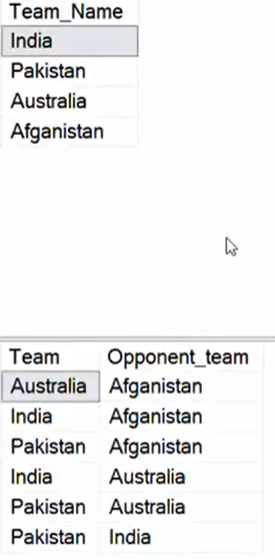

In [ ]:
# here first they ask to create table and then do query 
# first create  the table using insert 
# if you see we want combination each team with other teams without duplicate entries, so we can directly apply inner join  where t1.team != t2.team but we will have duplicates like inda,pakistan  and pakistan, india even if we find a way to drop them it's not efficient to first create and then drop
# instead first create row_numer for each entry and perform combination with it's below rows only. this will eliminate the duplicates 

# DROP TABLE IF EXISTS TEAMS;
# CREATE TABLE TEAMS (
#   (
    # Team_Name Varchar(100)  
# )
# INSERT INTO TEAMS
# VALUES ('India'),('Pakistan'),('Australia'),('Afganistan');


#### QUERY ###########
# WITH CTE AS (
# SELECT 
# Team_Name,
# ROW_NUMBER() OVER (ORDER BY Team_Name) RN
# FROM TEAMS
# )

# SELECT 
# T1.Team_Name as TEAM, 
# T2.Team_Name as OPPONENT_TEAM, 
# FROM CTE T1 
# INNER JOIN CTE T2 
# ON T1.RN < T2.RN 


# here we are re using the the table with row number so we wrapped under with by giving it a name CTE 




### question 2 
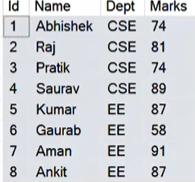

now we have 4 columns 
create 5th and 6th column using the below logic 

Logic for 5th Column
1. Find the ranking of student in each department such that <br>
    a. Marks should be in ascending order (means rank=1 for min marks) <br>
    b. Gap in ranks.
I

Logic for 6th Column <br>
a) Marks should be in descending order (means rank=1 for max marks) <br>
b) Find the ranking of student in each department such that there should be no gap between 2 ranks. <br>

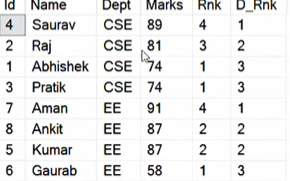

In [ ]:
# DROP TABLE IF EXISTS Class;
# CREATE TABLE Class
# (
# Id Int,
# Name Varchar(100),
# Dept Varchar(100),
# Marks Int
# )
# INSERT INTO Class
# Values
# (1, 'Abhishek', 'CSE', 74),
# (2, 'Raj', 'CSE',81),
# (3, 'Pratik', 'CSE', 74),
# (4, 'Saurav', 'CSE',89),
# (5, 'Kumar', 'EE', 87),
# (6, 'Gaurab', 'EE', 58),
# (7, 'Aman', 'ΕΕ',91),
# (8, 'Ankit', 'EE', 87)


##### query ##############

# SELECT *
# RANK() OVER(PARTITION BY DEPT ORDER BY MARKS ASC) AS Rnk
# DENSE_RANK() OVER(PARTITION BY DEPT ORDER BY MARKS DESC) D_Rnk
# FROM Class


### 3. Find the change in sales quantity w.r.t prev month sales for each product 

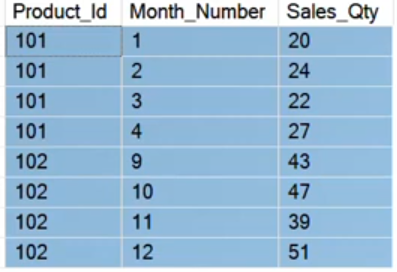


In [ ]:
# DROP TABLE IF EXISTS SALES;
# CREATE TABLE SALES
# (
# Product_Id Int,
# Month_Number Int,
# Sales_Qty Int
# )
# INSERT INTO SALES
# VALUES
# (101,1,20),
# (101,2,24),
# (101,3,22),
# (101,4,27),
# (102,9,43),
# (102,10,47),
# (102,11,39),
# (102,12,51)

# SELECT *
# (SALES QTY-Prev_Sales_Qty) as Diff_Sales_Qty
# FROM
# (
# SELECT *
# LAG(SALES QTY, 1, SALES S QTY, 1, SALES QTY) OVER(PARTITION BY Product_Id ORDER BY MONTH_NUMBER) AS Prev_Sales_Qty
# FROM SALES
# )a


# here LAG(column name, steps, default value when null)


### 4. IntraDay CDC 
intraday - multiple transactions happening in same day , 
CDC - change data capture 

find the active transation for each user with transaction start time , end time for each individual transaction .
Here transaction start time is same transactiondate colums, transaction end time is time before next transaction start time i.e., next transaction start time -1 second 
active transactions is last transaction you can consider 
for last transaction for each user we can take max future time here we have taken year

find the below input table and output table 
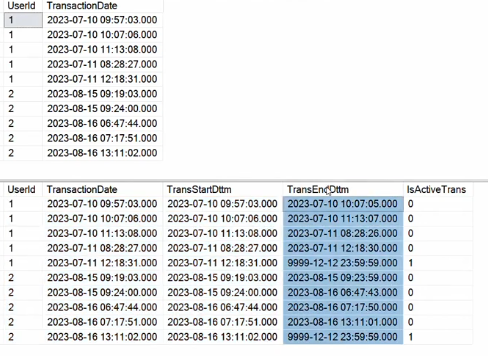

In [ ]:
# DROP TABLE IF EXISTS Transactions;
# CREATE TABLE Transactions
# (
# UserId INT,
# TransactionDate DATETIME
# )
# INSERT INTO Transactions
# VALUES
# (1, 2023-07-10 09:57:03),
# (1,2823-07-18 10:07:06),
# (1, 2023-07-18 11:13:08),
# (1, 2023-07-11 06:28:27'),
# (1, 2023-07-11 12:18:31),
# (2,2023-88-15 09:19:03"),
# (7, 2023-08-15 09:24:00),
# (2,2023-88-16 06:47:44'),
# (2,2023-88-16 07:17:51'),
# (2,2023-88-16 13:11:02)

# SELECT,
# CASE WHEN Trans EndDttm = '9999-12-12 23:59:59.000' THEN 1 ELSE 0 END AS IsActiveTrans
# FROM
# (

# SELECT 
# *, 
# TransactionDate as TransStartDttm,
# COALESCE (DATEADD(SECOND, -1, LEAD (TransactionDate) OVER(PARTITION BY UserId ORDER BY TransactionDate)), '9999-12-12 23:59:59') AS TransEndDttm
# FROM TRANSACTIONS
# ) a



### 5. Running Sum

find the running sum of order price for every customer 
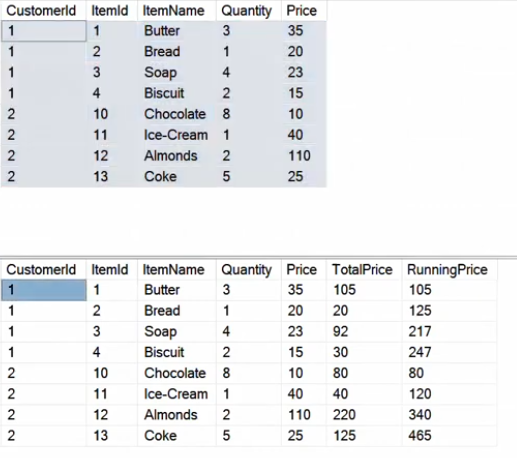


In [ ]:
# DROP TABLE IF EXISTS CustomerOrder;
# CREATE TABLE CustomerOrder
# (
# CustomerId INT,
# ItemId INT,
# ItemName VARCHAR(100),
# Quantity INT,
# Price INT
# )

# INSERT INTO CustomerOrder
# VALUES
# (1,1, Butter,3,35),
# (1,2, 'Bread', 1,20),
# (1,3, 'Soap', 4,23),
# (1,4, 'Biscuit', 2,15),
# (2,10, 'Chocolate', 8,10),
# (2,11, 'Ice-Cream', 1,40),
# (2,12, 'Almonds', 2,110),
# (2,13, 'Coke', 5,25)

# WITH CTE AS
# (
# SELECT *,
# (Quantity*Price) AS TotalPrice
# FROM CustomerOrder)
# SELECT *,
# SUM(TotalPrice) OVER (PARTITION BY CustomerId ORDER BY ItemId) AS RunningPrice
# FROM CTE

# OVER (PARTITION BY CustomerId ORDER BY ItemId) is same as OVER (PARTITION BY CustomerId ORDER BY ItemId rows between unbounded preceding and current row) which means for each customer id order by item id and take all rows from the beginning to current row and take sum of total price
# OVER (PARTITION BY CustomerId ORDER BY ItemId rows 1 preceding and current row) means for each customer id order by item id and take current row and previous row and take sum of total price

### 6.From given Itemprice table, find the first month and last month price for each item to analyse the variation of price 

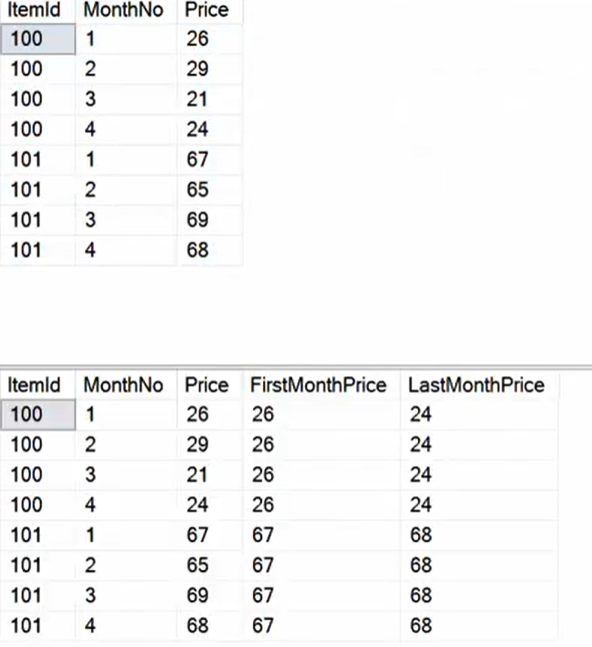

In [ ]:
### we can do this by applying windows functions rank() and taking conditional statement or case statment for firstmonth and lastmonth
### but we have inbuilt windows functions like first_value and last_value 

# SELECT *,
# FIRST_VALUE (Price) OVER(PARTITION BY ItemId Order By MonthNo) FirstMonthPrice, 
# LAST_VALUE (Price) OVER(PARTITION BY ItemId ORDER BY MonthNo) LastMonthPrice
# FROM ItemPrice

# but using the above we will get output like below 
# because while applying windows function, windows function will take all the rows in the window and apply the function on that window, so for each row that will be last value of that window  but here we want to take the last value of the window which is ordered by monthno, so we need to use rows between unbounded preceding and unbounded following to get the last value of the window which is ordered by monthno

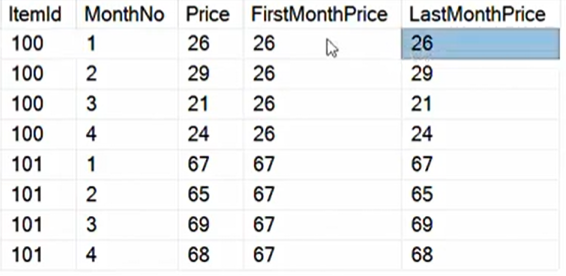

In [ ]:
# SELECT *,
# FIRST_VALUE (Price) OVER(PARTITION BY ItemId Order By MonthNo) FirstMonthPrice,
# LAST_VALUE (Price) OVER(PARTITION BY ItemId ORDER BY MonthNo ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING) LastMonthPrice 
# FROM ItemPrice

# this will give us the expected output 


### 7. From the given attendance log input table, wrtie a sql query to get the output as shown in output table 
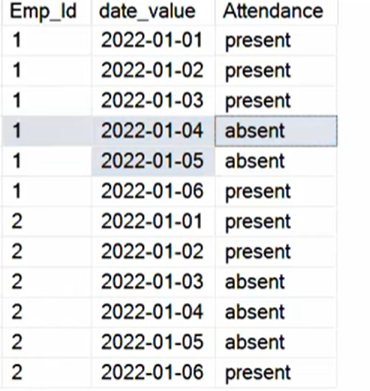
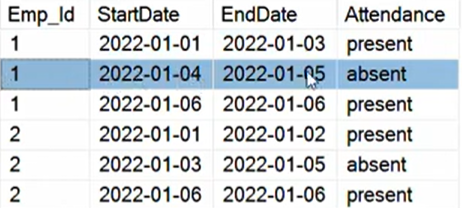

# approach
### first apply windows function by partioning on emp_id and attendance and windows function rank
### now every emp_id,attendance will have unique rank in thier window
### create an other column by subtracting the rank from the date so that continous date will have same value for date-rank 
### next group by that emp_id,attendance and date-rank and take min and max of date to get the continous streaks for each emp_id,attendance 
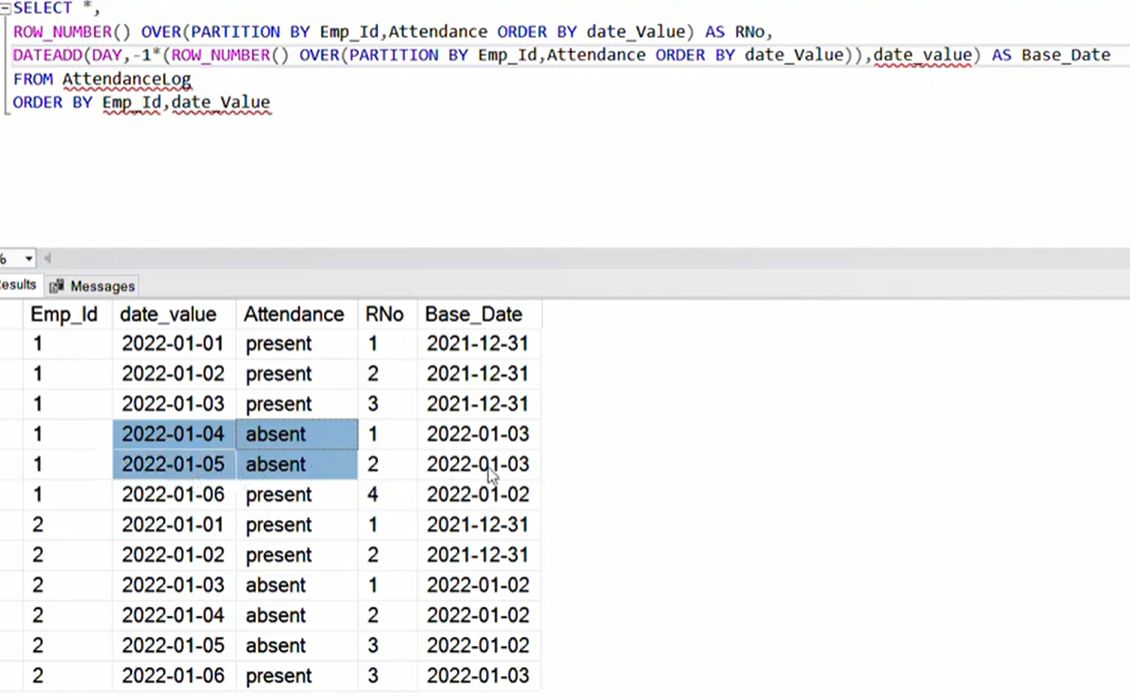




In [ ]:
# WITH CTE AS
# (SELECT *,
# ROW_NUMBER() OVER(PARTITION BY Emp_Id, Attendance ORDER BY date_Value) AS RNO,
# DATEADD(DAY,-1* (ROW_NUMBER() OVER(PARTITION BY Emp_Id, Attendance ORDER BY date_Value)), date value) AS Base_Date
# FROM AttendanceLog

# )
# SELECT Emp Id, MIN(date value) AS STARTDATE, MAX(date value) AS ENDDATE, Attendance FROM CTE
# GROUP BY Emp Id, Base_Date, Attendance
# ORDER BY Emp Id, STARTDATE

### 8. Forward fillinf Null values 
fill the null values to the nearest previous values 
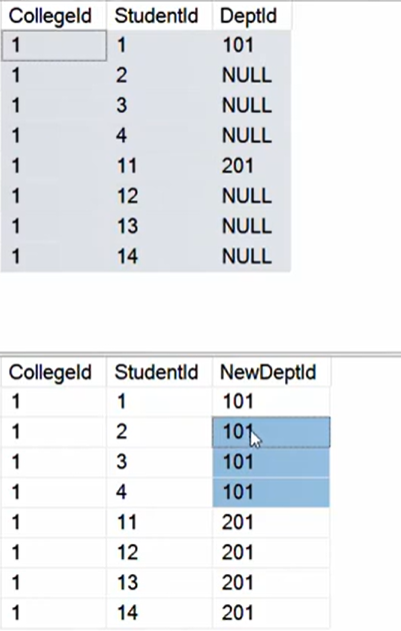

In [ ]:
# WITH CTE AS
# (
# SELECT
# COUNT(DeptId) OVER(ORDER BY StudentId) AS Cnt_DeptId
# FROM StudentDetail
# )
# SELECT *,
# FIRST_VALUE(DeptId) OVER(PARTITION BY Cnt_DeptId ORDER BY StudentId) AS New_Dept Id
# FROM CTE

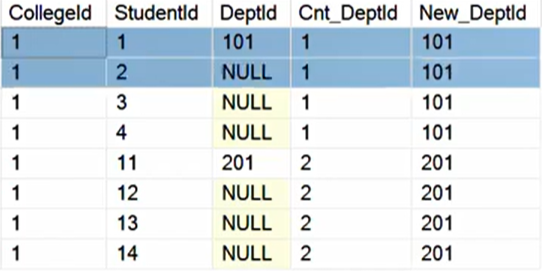

## Kotak mahindra interview questions 

In [18]:
import pandas as pd 

df = pd.read_excel("D:\Data Science\pandas\datasets\KPML.xlsx")
df.head()

<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Vishnu\AppData\Local\Temp\ipykernel_10816\3709738298.py:3: SyntaxWarning: invalid escape sequence '\D'
  df = pd.read_excel("D:\Data Science\pandas\datasets\KPML.xlsx")


,cust,Pincode,loan,loan start date,loan last reported date,dpd,loan amt,loan status
0,1,400034,housing loan,jan'24,Jan'26,000|xxx|030|000|,5 Crs,live
1,1,400034,used car loan,feb'19,Dec'24,045|090|056|000,4 lacs,closed
2,2,600006,new car loan,sep'25,nov'25,000|001|000,10 lacs,liv


In [52]:
res = df.groupby("cust",as_index=False).agg({'Pincode':'count'})
res

,cust,Pincode
0,1,2
1,2,1


### 1.create a new column on dpd column based on number of |

In [10]:
temp_df = df['dpd'].str.strip('|').str.split('|',expand=True)
temp_df

#here expand =True will give us a dataframe with each value in a separate column, if we dont use expand=True then we will get a series with each value in a list, so we need to use expand=True to get a dataframe with each value in a separate column

,0,1,2,3
0,000,xxx,030,000
1,045,090,056,000
2,000,001,000,None


In [11]:
temp_df.columns = [f"dpd_{i+1}" for i in range(temp_df.shape[1])]
temp_df

,dpd_1,dpd_2,dpd_3,dpd_4
0,000,xxx,030,000
1,045,090,056,000
2,000,001,000,None


In [40]:
# now we will concat the temp_df with original df to get the final dataframe with each value in a separate column
df = pd.concat([df,temp_df],axis=1)
df

,cust,Pincode,loan,loan start date,loan last reported date,dpd,loan amt,loan status,dpd_1,dpd_2,dpd_3,dpd_4
0,1,400034,housing loan,jan'24,Jan'26,000|xxx|030|000|,5 Crs,live,000,xxx,030,000
1,1,400034,used car loan,feb'19,Dec'24,045|090|056|000,4 lacs,closed,045,090,056,000
2,2,600006,new car loan,sep'25,nov'25,000|001|000,10 lacs,liv,000,001,000,None


### 2.return rows with cutomer = 1 and loan status = live 


In [34]:
df[(df['cust']==1) & df['loan status'].str.strip('').isin(['live','liv'])]


,cust,Pincode,loan,loan start date,loan last reported date,dpd,loan amt,loan status,dpd_1,dpd_2,dpd_3,dpd_4
0,1,400034,housing loan,jan'24,Jan'26,000|xxx|030|000|,5 Crs,live,000,xxx,030,000


### 3.convert loan start date , loan last reported date to pandas date time format



In [41]:
df['loan start date'] = pd.to_datetime(df['loan start date'].str.title(),format="%b'%y")
df['loan last reported date'] = pd.to_datetime(df['loan last reported date'].str.title(),format="%b'%y")
df

,cust,Pincode,loan,loan start date,loan last reported date,dpd,loan amt,loan status,dpd_1,dpd_2,dpd_3,dpd_4
0,1,400034,housing loan,2024-01-01,2026-01-01,000|xxx|030|000|,5 Crs,live,000,xxx,030,000
1,1,400034,used car loan,2019-02-01,2024-12-01,045|090|056|000,4 lacs,closed,045,090,056,000
2,2,600006,new car loan,2025-09-01,2025-11-01,000|001|000,10 lacs,liv,000,001,000,None
